# From soil samples to a soil organic carbon map and scenario totals

This tutorial follows a typical soil organic carbon (SOC) workflow on synthetic data, where the **true SOC field is known**,
so every step can be checked:

1. design a stratified sample (proportional vs Neyman allocation);
2. describe spatial structure with a variogram, after removing the land-use trend;
3. choose between inverse-distance weighting and regression kriging by cross-validation;
4. map SOC and its kriging uncertainty, and check against the truth;
5. summarise scenario outputs (as produced by RothC / GSOCseq runs) per stratum and in t CO₂.

All numbers are illustrative; they describe no real site. Runs offline in under a minute.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.ndimage import gaussian_filter

from soilcarbon import interp, sampling, scenarios, validate

plt.rcParams.update({"figure.dpi": 90})
rng = np.random.default_rng(11)

## 1. A synthetic landscape

A 6 × 4 km area on a 100 m grid, with three land-use strata of different SOC levels and spatially correlated variation
(correlation length of a few hundred metres).

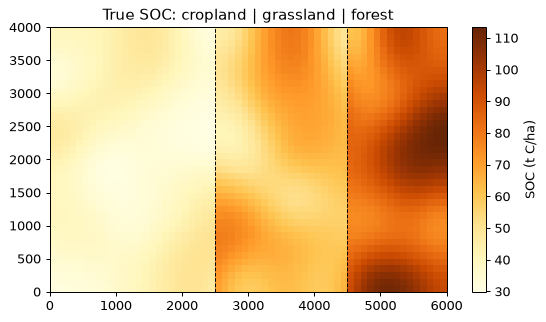

In [2]:
g = interp.grid((0, 0, 6000, 4000), resolution=100)
ny, nx = g.shape
xx, yy = np.meshgrid(g.x, g.y)
stratum = np.where(xx < 2500, "cropland", np.where(xx < 4500, "grassland", "forest"))
level = {"cropland": 40.0, "grassland": 60.0, "forest": 80.0}
smooth = gaussian_filter(rng.normal(0, 1, (ny, nx)), sigma=4)
smooth /= smooth.std()
spread = {"cropland": 5.0, "grassland": 9.0, "forest": 14.0}   # forest soils vary most
soc_true = np.vectorize(level.get)(stratum) + np.vectorize(spread.get)(stratum) * smooth

cells = pd.DataFrame({"x": xx.ravel(), "y": yy.ravel(), "stratum": stratum.ravel(), "soc_true": soc_true.ravel()})

fig, ax = plt.subplots(figsize=(6.5, 3.6))
im = ax.imshow(soc_true, extent=(0, 6000, 0, 4000), cmap="YlOrBr")
fig.colorbar(im, ax=ax, label="SOC (t C/ha)")
for xb in (2500, 4500):
    ax.axvline(xb, color="k", lw=0.8, ls="--")
ax.set_title("True SOC: cropland | grassland | forest")
plt.tight_layout()

## 2. Sampling design

60 samples, at least 2 per stratum. **Proportional** allocation follows stratum size; **Neyman** allocation also weights by
the expected variability (here from a prior map), which minimises the variance of the overall mean (Cochran 1977).
Rounding uses the largest-remainder method, so the totals are exact and no stratum is rounded away.

In [3]:
sizes = cells["stratum"].value_counts().sort_index()
prior_std = cells.groupby("stratum")["soc_true"].std()          # stands in for a prior SOC map
alloc = pd.DataFrame({
    "cells": sizes,
    "prior_std": prior_std.round(1),
    "proportional": sampling.allocate(sizes, 60, "proportional", minimum=2),
    "neyman": sampling.allocate(sizes, 60, "neyman", std=prior_std, minimum=2),
})
alloc

,cells,prior_std,proportional,neyman
stratum,,,,
cropland,1000,5.1,25,17
forest,600,11.0,15,21
grassland,800,8.4,20,22


In [4]:
sample = sampling.draw_stratified(cells, "stratum", alloc["neyman"], seed=3).copy()
sample["soc_obs"] = sample["soc_true"] + rng.normal(0, 2.0, len(sample))   # lab + field error
sample["set"] = sampling.split_stratified(sample, "stratum", test_fraction=0.25, seed=3)
train, test = sample[sample["set"] == "train"], sample[sample["set"] == "test"]
print(f"{len(train)} training and {len(test)} independent test samples")
sample.groupby(["stratum", "set"]).size().unstack()

45 training and 15 independent test samples


set,test,train
stratum,,
cropland,4,13
forest,5,16
grassland,6,16


## 3. Spatial structure: the variogram, and why the trend must go first

The variogram gives semivariances between pairs of training samples, binned by distance (Matheron's estimator).
A model is fitted to it by Cressie's (1985) weighted least squares:

- the **nugget** is short-range plus measurement variation;
- the **sill** is the total variance;
- the **range** is the distance beyond which samples are no longer correlated.

Ordinary kriging assumes the mean is the same everywhere. Here it is not: SOC levels differ between land uses.
The raw variogram therefore keeps rising with distance, and any fitted "range" would be meaningless.
**Regression kriging** (Hengl et al. 2007) handles this. It models the mean from a covariate (here the stratum), then krigs the
residuals, which are stationary.

,nugget,psill,range,model
spherical,0.0,67.633883,1115.073051,spherical
exponential,0.0,68.326309,1159.793515,exponential


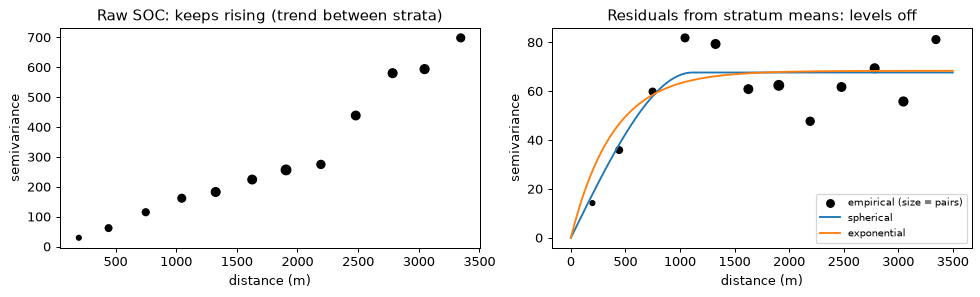

In [5]:
xy_train = train[["x", "y"]].to_numpy()
z_train = train["soc_obs"].to_numpy()
stratum_mean = train.groupby("stratum")["soc_obs"].mean()
resid = z_train - train["stratum"].map(stratum_mean).to_numpy()

raw_v = interp.empirical_variogram(xy_train, z_train, n_lags=12, max_dist=3500)
lags, gamma, counts = interp.empirical_variogram(xy_train, resid, n_lags=12, max_dist=3500)
models = {m: interp.fit_variogram(lags, gamma, counts, model=m) for m in ("spherical", "exponential")}

h = np.linspace(0, 3500, 200)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].scatter(raw_v[0], raw_v[1], s=10 + raw_v[2] / 2, color="k")
ax[0].set_title("Raw SOC: keeps rising (trend between strata)")
ax[1].scatter(lags, gamma, s=10 + counts / 2, color="k", label="empirical (size = pairs)")
for name, vg in models.items():
    ax[1].plot(h, interp.VARIOGRAM_MODELS[name](h, vg["nugget"], vg["psill"], vg["range"]), label=name)
ax[1].set_title("Residuals from stratum means: levels off")
ax[1].legend(fontsize=8)
for a in ax:
    a.set_xlabel("distance (m)")
    a.set_ylabel("semivariance")
plt.tight_layout()
pd.DataFrame(models).T

## 4. Choosing the method by cross-validation

Each sample is left out in turn and predicted from the rest (leave-one-out). For regression kriging the stratum means are also
recomputed without the left-out sample, so it never informs its own prediction. The variogram is fitted once on all
training residuals, a common and slightly optimistic simplification.

The scores are bias, RMSE, and Lin's concordance correlation coefficient (CCC). CCC measures agreement with the 1:1 line,
not just correlation.

In [6]:
def loo_regression_kriging(variogram=None):
    # Leave-one-out: stratum mean (+ kriged residual if a variogram is given) from the other samples only.
    out = np.empty(len(train))
    for i in range(len(train)):
        keep = np.arange(len(train)) != i
        others = train.iloc[keep]
        mu = others.groupby("stratum")["soc_obs"].mean()
        out[i] = mu[train["stratum"].iloc[i]]
        if variogram is not None:
            r = z_train[keep] - others["stratum"].map(mu).to_numpy()
            out[i] += interp.ordinary_kriging(xy_train[keep], r, xy_train[i : i + 1], variogram)[0][0]
    return out


loo = {
    "IDW (power 2)": interp.loocv(xy_train, z_train, "idw", power=2.0),
    "stratum mean only": loo_regression_kriging(None),
    "regression kriging, spherical": loo_regression_kriging(models["spherical"]),
    "regression kriging, exponential": loo_regression_kriging(models["exponential"]),
}
cv = pd.DataFrame({name: validate.agreement(z_train, p) for name, p in loo.items()}).T
cv[["n", "bias", "rmse", "ccc"]].astype(float).round(3)

,n,bias,rmse,ccc
IDW (power 2),45.0,0.287,8.650,0.916
stratum mean only,45.0,0.000,8.414,0.931
"regression kriging, spherical",45.0,-0.313,6.096,0.965
"regression kriging, exponential",45.0,-0.127,6.600,0.959


In [7]:
best = cv["rmse"].astype(float).idxmin()
print("lowest cross-validated RMSE:", best)
vg = models["exponential" if "exponential" in best else "spherical"]

def regression_kriging(xy_new, strata_new):
    pred_r, var_r = interp.ordinary_kriging(xy_train, resid, xy_new, vg)
    return pd.Series(strata_new).map(stratum_mean).to_numpy() + pred_r, var_r

pred_test, _ = regression_kriging(test[["x", "y"]].to_numpy(), test["stratum"].to_numpy())
print("independent test samples:")
pd.Series(validate.agreement(test["soc_obs"], pred_test))[["n", "bias", "rmse", "ccc"]].astype(float).round(3)

lowest cross-validated RMSE: regression kriging, spherical
independent test samples:


n       15.000
bias     1.910
rmse     4.695
ccc      0.972
dtype: float64

## 5. The map, its uncertainty, and the truth

The kriging variance is lowest near samples and grows with distance. Here the prediction can also be compared with the true field.

map RMSE vs truth: 5.57 t C/ha; cells where the truth lies within 1.96 kriging SD: 95 %


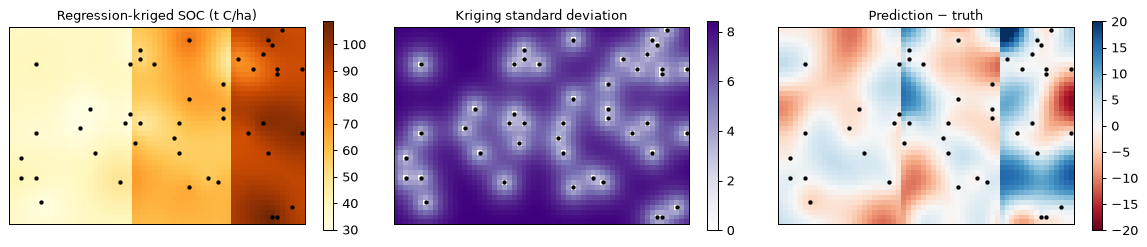

In [8]:
pred, var = regression_kriging(g.points(), stratum.ravel())
pred, sd = pred.reshape(g.shape), np.sqrt(var).reshape(g.shape)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.2))
for a, data, title, cmap in [(ax[0], pred, "Regression-kriged SOC (t C/ha)", "YlOrBr"),
                             (ax[1], sd, "Kriging standard deviation", "Purples"),
                             (ax[2], pred - soc_true, "Prediction − truth", "RdBu")]:
    kwargs = {"vmin": -20, "vmax": 20} if "truth" in title else {}
    im = a.imshow(data, extent=(0, 6000, 0, 4000), cmap=cmap, **kwargs)
    a.scatter(train["x"], train["y"], s=6, c="k")
    a.set_title(title, fontsize=10)
    a.set_xticks([])
    a.set_yticks([])
    fig.colorbar(im, ax=a, shrink=0.8)
plt.tight_layout()

err = (pred - soc_true).ravel()
inside = np.abs(err) <= 1.96 * sd.ravel()
print(f"map RMSE vs truth: {np.sqrt(np.mean(err**2)):.2f} t C/ha; "
      f"cells where the truth lies within 1.96 kriging SD: {100 * inside.mean():.0f} %")

The stratum boundaries are now kept sharp, because the mean comes from land use. The residual kriging fills in the smooth variation
within strata. Two limits to keep in mind:

- **Kriging smooths.** It reproduces the broad pattern, not every local detail.
- **The kriging variance covers the residuals only.** It leaves out the uncertainty of the stratum means. Here the coverage is
  close to the nominal 95 %, but with few samples per stratum the intervals can be too narrow.

## 6. Scenario outputs: change, additional sequestration, totals

Process models such as RothC, run in the GSOCseq framework (FAO 2022), give SOC per cell at the start (`soc_t0`), after 20 years of
business as usual (`soc_bau`) and under low, medium and high sustainable-management scenarios. The numbers below are invented
to show the calculations.

- **change** = scenario − t0
- **additional sequestration (delta)** = scenario − BAU, the gain attributable to the practice change
- **rates** = per year over the horizon
- stratum means are **area-weighted**, and totals multiply t C/ha by area (× 44/12 for t CO₂)

In this invented example, forest is left unchanged in every scenario, so its deltas are zero.

In [9]:
area_ha = (100 * 100) / 10_000
runs = pd.DataFrame({"stratum": stratum.ravel(), "area_ha": area_ha, "soc_t0": pred.ravel()})
bau_loss = runs["stratum"].map({"cropland": -0.10, "grassland": -0.02, "forest": 0.0})
runs["soc_bau"] = runs["soc_t0"] * (1 + bau_loss)
for name, gain in {"soc_low": 0.02, "soc_med": 0.06, "soc_high": 0.10}.items():
    runs[name] = runs["soc_bau"] * (1 + gain * (runs["stratum"] != "forest"))

out = scenarios.changes(runs, horizon_years=20)
print("cells violating BAU <= low <= med <= high:", int(scenarios.ordering_check(out)["any_violation"].sum()))
scenarios.area_weighted_summary(out, ["delta_soc_low", "delta_soc_med", "delta_soc_high", "delta_rate_soc_med"],
                                "area_ha", by="stratum").round(3)

cells violating BAU <= low <= med <= high: 0


,delta_soc_low,delta_soc_med,delta_soc_high,delta_rate_soc_med,area_ha
stratum,,,,,
cropland,0.673,2.020,3.366,0.101,1000.0
forest,0.000,0.000,0.000,0.000,600.0
grassland,1.196,3.589,5.982,0.179,800.0


In [10]:
scenarios.totals(out, ["delta_soc_low", "delta_soc_med", "delta_soc_high"], "area_ha", by="stratum", co2=True).round(0)

,delta_soc_low,delta_soc_med,delta_soc_high
stratum,,,
cropland,2468.0,7405.0,12342.0
forest,0.0,0.0,0.0
grassland,3509.0,10528.0,17546.0


**References:** Cochran (1977); Matheron (1963); Cressie (1985); Hengl, Heuvelink & Rossiter (2007), https://doi.org/10.1016/j.cageo.2007.05.001; Lin (1989); FAO (2022) GSOCseq technical manual,
https://doi.org/10.4060/cb2642en; Coleman & Jenkinson (1996) RothC, https://doi.org/10.1007/978-3-642-61094-3_17.
See the [README](../README.md) for the full list.